# Stage 3 Model Comparison — Design Reasoning

This notebook is one of a set of 8, each testing/comparing candidate AI models
for one stage of a manufacturing CAD-generation pipeline (custom starwheels —
rotary parts that feed bottles through capping machines). This notebook covers
**Stage 3 only** — turning a spec plus retrieved precedents into several
complete candidate parameter sets, each with an explicit trade-off rationale
— using the source note's own worked example (the CAP-16 / 500 ml PET bottle
/ 16-pocket starwheel job).

> *"This is the one stage where model scale genuinely pays. The task is
> weighing trade-offs — cost against dimensional stability, tight tolerance
> against forgiveness — and articulating why. Weak models produce parameter
> sets that look fine and rationales that are generic."* — `model_types_by_stage.md`

**This is a fundamentally harder thing to grade than Stage 4.** Stage 4's
sibling notebook can check its candidates against a real OCCT geometry
kernel — a script either produces the right solid or it doesn't, and that's
checkable by arithmetic. Stage 3 produces *reasoning in prose*. There is no
kernel that returns "this rationale is correct." So instead of mechanical
correctness, this notebook builds a **grounding-based validation harness**:
it checks things a genuinely reasoning model should get right and a
shallow/templated model tends to get wrong — does the output satisfy the
hard machine/material constraints, and does the *rationale* actually engage
with the retrieved precedent evidence it was given, rather than just
restating the parameter it's supposed to be justifying. Section 5 spells out
exactly what this can and can't prove — treat every "reasoning score" below
as a proxy, not a ground truth.

**This sandbox has no outbound network access** to model-hosting APIs
(OpenRouter, etc.), so the cells below are pre-executed here using only the
local baseline adapters (proving the harness itself works correctly), while
the real OpenRouter candidate shows as `skipped`/`generation_failed` in *this*
run. Section 9 covers what's needed to run it for real, with a real API key,
somewhere with network access.

## 0. Setup

Installs anything missing. No heavy ML dependencies needed here — Stage 3
candidates are called over an API (or stand in as local Python functions),
there's no local model weights to load, unlike Stage 4's Text-to-CadQuery
adapter.

In [1]:
import sys
import subprocess

def _ensure(*packages):
    # Import-or-install: cheap no-op on Colab (these are usually preinstalled),
    # but makes the notebook self-contained on a bare kernel too.
    for pkg in packages:
        mod_name = pkg.split("==")[0].replace("-", "_")
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# pandas      -> comparison table in Section 7
# matplotlib  -> score chart in Section 7
_ensure("pandas", "matplotlib")
print("dependencies ready")

dependencies ready


### Credentials

**Don't hardcode API keys directly into a notebook cell** — a notebook with a
key pasted into `os.environ[...] = "sk-or-..."` carries that key in plain
text in the `.ipynb` file itself (including if you save, git-commit, or send
the file to anyone), and Jupyter/Colab has no way to redact it after the
fact. The cell below uses `getpass` instead: it prompts you once per session
and the key never gets written into the notebook or its outputs. If you've
already pasted a real key into a cell before, treat that key as burned and
rotate it on OpenRouter's dashboard.

In [2]:
import os
from getpass import getpass

# Prompts only if OPENROUTER_API_KEY isn't already set in the environment --
# safe to re-run this cell, it won't ask twice in the same session.
if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass("OpenRouter API key (leave blank to skip real candidates): ")

In [3]:
# stdlib
import json                # (de)serializing the Stage 3 input/output payloads
import os                   # env vars: OPENROUTER_API_KEY
import re                    # extracting JSON from markdown-fenced model output
import time                   # generation timing per trial
import urllib.error            # (kept for callers that want to catch it explicitly)
import urllib.request           # OpenRouter HTTP calls without adding a requests dependency

# third-party
import pandas as pd     # comparison table in Section 7

print("stdlib + pandas ready")

stdlib + pandas ready


## 1. Stage 3 input

Stage 3 sits between retrieval (Stage 2) and CAD generation (Stage 4). Its
input is everything a human design engineer would want on their desk before
committing to parameters: the customer spec, the retrieved precedents (with
their service outcomes), the hard machine constraints, and a small material
table. Every candidate model below gets the identical input.

The two precedents are the important part of this input. `SW-10231` is
geometrically similar *and* ran clean for 31 months — it's the design basis.
`SW-10884` is even more geometrically similar (tighter clearance, closer to
what a naive optimizer might reach for) but **failed in service** — bottles
bound in the pockets at speed. A model that just pattern-matches on
similarity and picks the tighter clearance because it looks more "precise"
is falling into exactly the trap the source doc warns about. A model that
actually reasons about the trade-off should notice the outcome data, not
just the geometry.

In [4]:
# Stage 1 output (spec extraction) -- verbatim from model_types_by_stage.md
STAGE1_SPEC = {
    "machine_id": "CAP-16",
    "part_family": "starwheel",
    "target_speed_cpm": 380,
    "container": {
        "description": "500 ml PET still water bottle",
        "body_diameter_mm": 64.0,
        "ovality_mm": None,
        "height_mm": 210,
        "neck_finish": "PCO-1881",
        "closure": "28 mm plastic screw",
        "material": "PET",
        "filled_weight_g": 520,
        "shape": None,
    },
    "unresolved_questions": ["Body ovality tolerance was not supplied. Confirm the maximum ovality."],
    "feasibility_flags": [],
}

# Stage 2 output (retrieval) -- verbatim from model_types_by_stage.md.
# SW-10231 is the design basis (ran clean 31 months). SW-10884 is a WARNING,
# not a design basis: geometrically close (same pocket_count) but failed in
# service specifically because clearance was too tight (0.35mm vs SW-10231's
# 0.8mm) -- bottles bound in the pockets at speed. Stage 3's rationale should
# engage with both, not just the higher-similarity-score one.
STAGE2_PRECEDENTS = [
    {
        "rank": 1, "part_number": "SW-10231", "similarity_score": 0.96, "outcome_weight": 1.0,
        "parameters": {"pocket_count": 16, "pocket_clearance_mm": 0.8, "material_id": "UHMW-PE"},
        "outcome": {"first_article_pass": True, "jam_rate_per_10k": 1.2, "service_life_months": 31},
    },
    {
        "rank": 2, "part_number": "SW-10884", "similarity_score": 0.81, "outcome_weight": 0.3,
        "parameters": {"pocket_count": 16, "pocket_clearance_mm": 0.35},
        "outcome": {"first_article_pass": False, "jam_rate_per_10k": 9.6,
                    "commissioning_note": "bottles binding in pockets at speed"},
    },
]

# Machine constraints -- not in the source doc's Stage 3 example verbatim, but
# a real Stage 3 input needs the hard limits a design must respect. CAP-16's
# station count (16) is the one hard constraint every candidate is graded
# against in Section 5 -- same idea as Stage 4's parameter checks.
MACHINE_CONSTRAINTS = {
    "CAP-16": {
        "station_count": 16,          # pocket_count MUST equal this -- synchronous transfer
        "max_speed_cpm": 450,
        "max_wheel_od_mm": 900,       # envelope clearance inside the machine frame
    }
}

# House material table -- small, hardcoded, used by the validator to catch a
# hallucinated material_id (e.g. a plausible-sounding polymer name that isn't
# actually in the shop's approved list).
MATERIAL_TABLE = {
    "UHMW-PE": {"food_contact": True, "friction_class": "low", "relative_cost": 1.0},
    "Acetal/POM": {"food_contact": True, "friction_class": "medium", "relative_cost": 1.4},
    "PTFE": {"food_contact": True, "friction_class": "very_low", "relative_cost": 3.2},
    "Nylon 6/6": {"food_contact": True, "friction_class": "medium", "relative_cost": 1.1},
    "Stainless 316": {"food_contact": True, "friction_class": "high", "relative_cost": 4.5},
}

STAGE3_PROMPT = f'''You are a design engineer producing candidate parameter sets for a
rotary starwheel that feeds bottles through a capping machine.

SPEC (from intake):
{json.dumps(STAGE1_SPEC, indent=2)}

RETRIEVED PRECEDENTS (from the parts library, most similar first):
{json.dumps(STAGE2_PRECEDENTS, indent=2)}

MACHINE CONSTRAINTS:
{json.dumps(MACHINE_CONSTRAINTS["CAP-16"], indent=2)}

APPROVED MATERIALS (food-contact qualified):
{json.dumps(MATERIAL_TABLE, indent=2)}

Produce 1-3 candidate designs as a JSON array. Each candidate must have this exact shape:
{{
  "branch_id": "A",
  "template_family": "starwheel_round_pocket_v3",
  "parameters": {{
    "pocket_count": <int, MUST equal the machine's station_count>,
    "pcd_mm": <float>,
    "pocket_radius_mm": <float>,
    "pocket_clearance_mm": <float>,
    "web_thickness_mm": <float>,
    "rim_mm": <float>,
    "outer_diameter_mm": <float, = pcd_mm + 2*pocket_radius_mm + 2*rim_mm>,
    "lead_in_chamfer_mm": <float>,
    "material_id": "<must be one of the approved materials listed above>"
  }},
  "rationale": {{
    "pocket_count": "<why this count>",
    "pocket_clearance_mm": "<why this clearance -- you are EXPECTED to explicitly
       weigh the two retrieved precedents against each other: SW-10231 ran clean
       for 31 months at 0.8mm clearance; SW-10884 failed in service (bottles
       binding at speed) at 0.35mm clearance. State which one you are treating
       as the design basis and which as a warning, and why.>",
    "material_id": "<why this material -- weigh cost against the friction/wear
       requirement>"
  }},
  "risk_flags": [<list of strings -- REQUIRED to be non-empty if your parameters
     land closer to the FAILED precedent (SW-10884, 0.35mm) than the successful
     one (SW-10231, 0.8mm) on any dimension that mattered to that failure>]
}}

Rules:
- pocket_count MUST equal the machine's station_count -- transfer must stay synchronous.
- material_id MUST be one of the approved materials listed above -- do not invent one.
- outer_diameter_mm MUST equal pcd_mm + 2*pocket_radius_mm + 2*rim_mm.
- Rationale is not optional decoration: ground it in the specific precedent data given
  above (part numbers, clearances, outcomes), not generic engineering language.
- If your own parameters carry real risk (e.g. a tight clearance closer to the failed
  precedent than the successful one), say so in risk_flags. An empty risk_flags list on
  a risky design is worse than an honest one.

Output ONLY the JSON array, no commentary before or after.
'''

print(STAGE3_PROMPT)

You are a design engineer producing candidate parameter sets for a
rotary starwheel that feeds bottles through a capping machine.

SPEC (from intake):
{
  "machine_id": "CAP-16",
  "part_family": "starwheel",
  "target_speed_cpm": 380,
  "container": {
    "description": "500 ml PET still water bottle",
    "body_diameter_mm": 64.0,
    "ovality_mm": null,
    "height_mm": 210,
    "neck_finish": "PCO-1881",
    "closure": "28 mm plastic screw",
    "material": "PET",
    "filled_weight_g": 520,
    "shape": null
  },
  "unresolved_questions": [
    "Body ovality tolerance was not supplied. Confirm the maximum ovality."
  ],
  "feasibility_flags": []
}

RETRIEVED PRECEDENTS (from the parts library, most similar first):
[
  {
    "rank": 1,
    "part_number": "SW-10231",
    "similarity_score": 0.96,
    "outcome_weight": 1.0,
    "parameters": {
      "pocket_count": 16,
      "pocket_clearance_mm": 0.8,
      "material_id": "UHMW-PE"
    },
    "outcome": {
      "first_article_pass":

## 2. Candidate models under test

Researched against the three candidates named in `model_types_by_stage.md`
Stage 3 section (GLM-5.2, DeepSeek V4, Qwen3.6-27B "if constrained to one
GPU"). Slugs and pricing below were verified directly against each model's
own OpenRouter page, then cross-checked against OpenRouter's
`/api/v1/models/{author}/{slug}/endpoints` listing (per-provider pricing
varies; the price quoted is the representative default shown on the model's
own page — see References for the exact per-provider breakdown each URL
returned).

| Adapter | Represents | How it runs | Source |
|---|---|---|---|
| `reference_grounded` | Non-LLM template baseline — well-grounded, constraint-satisfying | Local, no model | this notebook |
| `local_good_llm` | Stand-in for a competent reasoning model | Local, no model | — |
| `local_shallow_llm` | Stand-in for the failure mode the source doc warns about | Local, no model | — |
| `glm_5_2` | **Real candidate.** Z.ai's flagship reasoning-tier model | OpenRouter API, `z-ai/glm-5.2` — $0.50/M input, $3.15/M output, 1M context | [OpenRouter](https://openrouter.ai/z-ai/glm-5.2) |
| `deepseek_v4_pro` | **Real candidate.** DeepSeek's flagship reasoning model (see substitution note below) | OpenRouter API, `deepseek/deepseek-v4-pro` — ~$0.52/M input, ~$1.04/M output, 1M context, supports `high`/`xhigh` reasoning effort | [OpenRouter](https://openrouter.ai/deepseek/deepseek-v4-pro) |
| `qwen3_6_27b` | **Real candidate.** The "one GPU" fallback option named in the source doc | OpenRouter API, `qwen/qwen3.6-27b` — $0.30/M input, $2/M output, 262K context | [OpenRouter](https://openrouter.ai/qwen/qwen3.6-27b) |

**Substitution note on DeepSeek V4.** The source doc just says "DeepSeek V4"
without a variant. OpenRouter currently lists this generation as two
distinct SKUs — `deepseek-v4-pro` (full reasoning model, `high`/`xhigh`
reasoning effort) and `deepseek-v4-flash` (a 284B-total/13B-active MoE
optimized for throughput, roughly 9x cheaper). Since Stage 3 is explicitly
the stage where "model scale genuinely pays" and the other two named
candidates (GLM-5.2, Qwen3.6-27B) are both full-size models, this notebook
uses **`deepseek-v4-pro`** as the closer match to the source doc's intent,
not the Flash variant. If cost is the binding constraint in production,
`deepseek-v4-flash` is worth benchmarking too — see Section 9.

All three adapters below share the same OpenRouter chat-completions client
(Section 4) since all three model IDs are confirmed live, chat-style
endpoints on the same platform — unlike Stage 4's CAD-Coder, there's no
architecture mismatch to document as an exclusion here.

## 3. Local baseline adapters

Non-network stand-ins used to prove the validation harness itself works:
one correct-by-construction reference plus a second, differently-worded but
equally well-grounded alternative, and one that reproduces the exact
"plausible but generic" failure mode the source doc warns about -- a
parameter set that *looks* fine and a rationale that never actually engages
with the precedent evidence it was given.

In [5]:
# Every adapter in this notebook shares one signature: (stage3_input_dict, prompt_str)
# -> list-of-candidate-dicts (parsed JSON, matching the schema in STAGE3_PROMPT).
# That's what lets Section 5 call all six candidates through the same loop.

def reference_grounded(stage3_input, prompt):
    '''A hand-written, correct-by-construction candidate: parameters satisfy every
    hard constraint, and every rationale entry explicitly cites the retrieved
    precedent evidence it is built on. This is the 'no model, house engineer'
    baseline every candidate model should be measured against.'''
    return [{
        "branch_id": "A",
        "template_family": "starwheel_round_pocket_v3",
        "parameters": {
            "pocket_count": 16,
            "pcd_mm": 620,
            "pocket_radius_mm": 32.8,
            "pocket_clearance_mm": 0.8,
            "web_thickness_mm": 55.36,
            "rim_mm": 8.0,
            "outer_diameter_mm": 701.6,
            "lead_in_chamfer_mm": 2.0,
            "material_id": "UHMW-PE",
        },
        "rationale": {
            "pocket_count": "Matches the capper's 16 stations (CAP-16); transfer must be synchronous.",
            "pocket_clearance_mm": (
                "0.8 mm, matching SW-10231, which ran clean for 31 months at this exact "
                "clearance. SW-10884 used 0.35 mm and failed in service (bottles binding "
                "in pockets at speed) -- treating SW-10231 as the design basis and SW-10884 "
                "as a warning against tightening clearance further."
            ),
            "material_id": (
                "UHMW-PE for low friction on PET in a dry environment; cheapest approved "
                "option (relative_cost 1.0) that meets food contact, matching SW-10231's "
                "material choice."
            ),
        },
        "risk_flags": [],
    }]


def local_good_llm(stage3_input, prompt):
    '''A differently-worded but equally well-grounded second candidate -- simulates a
    strong reasoning model proposing a genuine alternative (Acetal/POM instead of
    UHMW-PE) while still grounding its clearance choice in the same precedent data
    and being honest that the alternative carries a wear-life tradeoff.'''
    return [{
        "branch_id": "B",
        "template_family": "starwheel_round_pocket_v3",
        "parameters": {
            "pocket_count": 16,
            "pcd_mm": 620,
            "pocket_radius_mm": 32.8,
            "pocket_clearance_mm": 0.75,
            "web_thickness_mm": 55.36,
            "rim_mm": 8.0,
            "outer_diameter_mm": 701.6,
            "lead_in_chamfer_mm": 2.0,
            "material_id": "Acetal/POM",
        },
        "rationale": {
            "pocket_count": "16 stations to stay synchronous with CAP-16; this is not negotiable per the machine constraints.",
            "pocket_clearance_mm": (
                "0.75 mm, close to SW-10231's proven 0.8 mm rather than SW-10884's 0.35 mm, "
                "which failed with bottles binding at speed. Trimmed 0.05 mm below the SW-10231 "
                "precedent for a slightly tighter transfer at 380 cpm; flagged as a minor risk below."
            ),
            "material_id": (
                "Acetal/POM traded up from UHMW-PE (relative_cost 1.4 vs 1.0) for better "
                "dimensional stability at the tighter clearance; medium friction class is "
                "an accepted tradeoff in this dry PET environment."
            ),
        },
        "risk_flags": [
            "Clearance (0.75mm) is slightly tighter than the proven SW-10231 precedent (0.8mm) -- recommend first-article run before full production commit."
        ],
    }]


def local_shallow_llm(stage3_input, prompt):
    '''Simulates the failure mode the source doc warns about: "parameter sets that
    look fine and rationales that are generic." Parameters superficially resemble a
    real design (right pocket_count, plausible-looking numbers) but the clearance is
    pulled toward the FAILED precedent (SW-10884's 0.35mm) rather than the successful
    one, the rationale never mentions either precedent by name or engages with the
    outcome data, and risk_flags is left empty despite the risky clearance -- exactly
    the "confident and wrong" pattern this whole 8-notebook project is testing for.'''
    return [{
        "branch_id": "C",
        "template_family": "starwheel_round_pocket_v3",
        "parameters": {
            "pocket_count": 16,
            "pcd_mm": 620,
            "pocket_radius_mm": 33.1,
            "pocket_clearance_mm": 0.4,   # much closer to SW-10884 (0.35, FAILED) than SW-10231 (0.8, worked)
            "web_thickness_mm": 55.0,
            "rim_mm": 8.0,
            "outer_diameter_mm": 701.6,
            "lead_in_chamfer_mm": 2.0,
            "material_id": "UHMW-PE",
        },
        "rationale": {
            "pocket_count": "16 pockets is standard for this part family.",
            "pocket_clearance_mm": "0.4 mm is a reasonable clearance value for a pocket of this size.",
            "material_id": "UHMW-PE is a commonly used material for parts like this.",
        },
        "risk_flags": [],   # the bug: parameters are risky (clearance near the failed precedent) but nothing flags it
    }]

## 4. Real candidate adapters

All three real candidates (`glm_5_2`, `deepseek_v4_pro`, `qwen3_6_27b`) go
through the same OpenRouter chat-completions client, requesting the
multi-candidate JSON array described in `STAGE3_PROMPT` and parsing it out
of the response (models routinely wrap JSON in markdown fences or add a
sentence of commentary, so extraction can't assume the whole response is
clean JSON).

`DeepSeek V4 Pro` supports an explicit reasoning-effort parameter
(`high`/`xhigh`, per its OpenRouter page); this notebook requests `high` to
keep cost bounded while still using its reasoning mode, since Stage 3 is
specifically the trade-off-reasoning stage.

In [6]:
def _extract_json_array(text):
    '''Models routinely wrap JSON in markdown fences with commentary before/after --
    pull out the fenced block if present, then parse. Falls back to scanning for the
    first top-level [...] span if there's no fence at all.'''
    fenced = re.search(r"```(?:json)?\s*(\[.*?\])\s*```", text, re.DOTALL)
    candidate = fenced.group(1) if fenced else None
    if candidate is None:
        bracket = re.search(r"(\[.*\])", text, re.DOTALL)
        candidate = bracket.group(1) if bracket else text
    return json.loads(candidate)


def _openrouter_chat(model_id, prompt, timeout=90, extra_body=None):
    '''Minimal OpenRouter chat-completions client using only the stdlib (no `requests`
    dependency). Raises RuntimeError immediately if no key is set, rather than letting
    urllib fail with a confusing low-level error later.'''
    api_key = os.environ.get("OPENROUTER_API_KEY")
    if not api_key:
        raise RuntimeError("OPENROUTER_API_KEY not set")
    body = {
        "model": model_id,
        "messages": [{"role": "user", "content": prompt}],
        "temperature": 0.3,     # low but nonzero -- deterministic-ish, still lets N trials show variance
    }
    if extra_body:
        body.update(extra_body)
    payload = json.dumps(body).encode()
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/chat/completions",
        data=payload,
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
        },
        method="POST",
    )
    # NOTE: this raises urllib.error.HTTPError on non-2xx (e.g. 402 = no/negative
    # credit balance, 404 = bad model id) -- run_trials() in Section 5 catches it
    # and records it as a failed trial instead of crashing the whole comparison.
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        data = json.loads(resp.read().decode())
    return data["choices"][0]["message"]["content"]


def glm_5_2(stage3_input, prompt):
    # Verified model id via https://openrouter.ai/z-ai/glm-5.2
    return _extract_json_array(_openrouter_chat("z-ai/glm-5.2", prompt))


def deepseek_v4_pro(stage3_input, prompt):
    # Verified model id via https://openrouter.ai/deepseek/deepseek-v4-pro
    # reasoning.effort="high" -- keeps cost bounded vs. "xhigh" while still using
    # the model's reasoning mode, appropriate for Stage 3's trade-off-weighing task.
    return _extract_json_array(_openrouter_chat(
        "deepseek/deepseek-v4-pro", prompt, extra_body={"reasoning": {"effort": "high"}}
    ))


def qwen3_6_27b(stage3_input, prompt):
    # Verified model id via https://openrouter.ai/qwen/qwen3.6-27b
    # -- the "if constrained to one GPU" fallback option named in the source doc.
    return _extract_json_array(_openrouter_chat("qwen/qwen3.6-27b", prompt))

## 5. Validation harness

**Read this before trusting any score below.** Stage 4's sibling notebook
grades a generated CadQuery script against a real geometry kernel: the
volume either matches or it doesn't, the bore is either open or it isn't.
There is no equivalent oracle for "is this trade-off reasoning sound." What
follows is a **grounding-based proxy**, not a ground-truth check, built from
four dimensions:

1. **Schema validity** — valid JSON; has `branch_id`, `template_family`,
   `parameters` (with the expected keys), `rationale` (covering at minimum
   `pocket_count`, `pocket_clearance_mm`, `material_id`), `risk_flags`.
2. **Constraint satisfaction** — `parameters.pocket_count` equals the
   machine's station count (16, from `machine_id: CAP-16`, hardcoded in
   `MACHINE_CONSTRAINTS` above); `outer_diameter_mm` equals `pcd_mm +
   2*pocket_radius_mm + 2*rim_mm` when `rim_mm` is present; `material_id` is
   a real material from `MATERIAL_TABLE`, not a hallucinated name.
3. **Grounding check (the important one)** — does `rationale.pocket_clearance_mm`
   actually reference the retrieved precedent evidence, or does it just
   restate the number? Implemented as a keyword heuristic: does the text
   mention a precedent part number (`SW-10231`, `SW-10884`) or an
   outcome-relevant word (`clean`, `bind`, `fail`, `jam`, `precedent`)?
   Deliberately **not** including the bare word "clearance" itself in that
   list — every rationale for `pocket_clearance_mm` mentions "clearance"
   tautologically (it's the field being justified), so that word alone would
   make the check pass by default and defeat its purpose. This is still just
   a heuristic, not semantic understanding — a model could game it by
   dropping "SW-10231" into an otherwise-generic sentence. It's scored as its
   own dimension precisely so a design can pass schema+constraints and still
   visibly fail grounding, which is exactly the "looks fine, reasoning is
   generic" failure mode the source doc names.
4. **Risk awareness** — if `pocket_clearance_mm` sits closer to the FAILED
   precedent (SW-10884, 0.35 mm) than the successful one (SW-10231, 0.8 mm),
   is `risk_flags` non-empty? An empty `risk_flags` list on a risky design is
   itself the finding — a model that is confidently wrong, which is the
   pattern this whole 8-notebook project exists to catch.

Each candidate gets a per-dimension pass/fail plus an overall verdict.
**None of this proves the design is *correct*** — it proves the model
engaged with the constraints and evidence it was given. A model could
satisfy all four checks with a design that's still a bad engineering choice
in ways this heuristic can't see, and conversely a genuinely excellent
rationale phrased unusually could get marked "generic" by the keyword
check. Treat the scores as *evidence*, the way Stage 5's real validation
treats a candidate before final human sign-off -- not as the final word.

In [7]:
STATION_COUNT = MACHINE_CONSTRAINTS["CAP-16"]["station_count"]
GOOD_CLEARANCE_MM = STAGE2_PRECEDENTS[0]["parameters"]["pocket_clearance_mm"]   # SW-10231, 0.8, worked
BAD_CLEARANCE_MM = STAGE2_PRECEDENTS[1]["parameters"]["pocket_clearance_mm"]     # SW-10884, 0.35, failed
GOOD_PRECEDENT_PN = STAGE2_PRECEDENTS[0]["part_number"]
BAD_PRECEDENT_PN = STAGE2_PRECEDENTS[1]["part_number"]

GROUNDING_KEYWORDS = [
    GOOD_PRECEDENT_PN.lower(), BAD_PRECEDENT_PN.lower(),
    "clean", "bind", "binding", "fail", "jam", "precedent",
]
# NOTE: deliberately NOT including the bare word "clearance" here -- every rationale
# for pocket_clearance_mm mentions "clearance" tautologically (it's the field being
# justified), so that word alone would make this check pass-by-default and defeat
# its purpose. Keywords below are ones that only show up when the text actually
# engages with precedent evidence: a part number, an outcome, or the word "precedent"
# itself.

REQUIRED_PARAM_KEYS = {
    "pocket_count", "pcd_mm", "pocket_radius_mm", "pocket_clearance_mm",
    "web_thickness_mm", "outer_diameter_mm", "material_id",
}
REQUIRED_RATIONALE_KEYS = {"pocket_count", "pocket_clearance_mm", "material_id"}


def _check_schema(candidate, reasons):
    if not isinstance(candidate, dict):
        reasons.append("candidate is not a JSON object")
        return False
    ok = True
    for key in ("branch_id", "template_family", "parameters", "rationale", "risk_flags"):
        if key not in candidate:
            reasons.append(f"missing top-level key: {key}")
            ok = False
    params = candidate.get("parameters", {})
    if not isinstance(params, dict):
        reasons.append("parameters is not an object")
        ok = False
    else:
        missing = REQUIRED_PARAM_KEYS - set(params.keys())
        if missing:
            reasons.append(f"parameters missing keys: {sorted(missing)}")
            ok = False
    rationale = candidate.get("rationale", {})
    if not isinstance(rationale, dict):
        reasons.append("rationale is not an object")
        ok = False
    else:
        missing = REQUIRED_RATIONALE_KEYS - set(rationale.keys())
        if missing:
            reasons.append(f"rationale missing entries for: {sorted(missing)}")
            ok = False
    if not isinstance(candidate.get("risk_flags"), list):
        reasons.append("risk_flags is not a list")
        ok = False
    return ok


def _check_constraints(candidate, reasons):
    params = candidate.get("parameters", {})
    ok = True

    pocket_count = params.get("pocket_count")
    if pocket_count != STATION_COUNT:
        reasons.append(f"pocket_count={pocket_count!r} != machine station_count={STATION_COUNT}")
        ok = False

    pcd = params.get("pcd_mm")
    r = params.get("pocket_radius_mm")
    rim = params.get("rim_mm")
    od = params.get("outer_diameter_mm")
    if all(isinstance(v, (int, float)) for v in (pcd, r, rim, od)):
        expected_od = pcd + 2 * r + 2 * rim
        if abs(expected_od - od) > 0.5:
            reasons.append(f"outer_diameter_mm={od} != pcd_mm+2*pocket_radius_mm+2*rim_mm={expected_od:.2f}")
            ok = False
    # rim_mm not supplied -> can't check this sub-condition; not penalized on its own.

    material = params.get("material_id")
    if material not in MATERIAL_TABLE:
        reasons.append(f"material_id={material!r} is not in the approved MATERIAL_TABLE (possible hallucination)")
        ok = False

    return ok


def _check_grounding(candidate, reasons):
    '''Heuristic only -- see Section 5 markdown. Checks whether the clearance
    rationale text engages with the retrieved precedent evidence at all.'''
    rationale = candidate.get("rationale", {})
    text = str(rationale.get("pocket_clearance_mm", "")).lower()
    grounded = any(kw in text for kw in GROUNDING_KEYWORDS)
    if not grounded:
        reasons.append(
            "rationale.pocket_clearance_mm does not reference any precedent part number "
            "or outcome-relevant keyword (SW-10231/SW-10884/clean/bind/fail/jam/precedent) -- "
            "reads as generic, not evidence-grounded"
        )
    return grounded


def _check_risk_awareness(candidate, reasons):
    '''If the clearance is closer to the FAILED precedent than the successful one,
    risk_flags must be non-empty. This is the "confident and wrong" check.'''
    params = candidate.get("parameters", {})
    clearance = params.get("pocket_clearance_mm")
    risk_flags = candidate.get("risk_flags", [])
    if not isinstance(clearance, (int, float)):
        return True   # can't evaluate distance -- don't penalize awareness on a schema failure already caught above
    dist_to_bad = abs(clearance - BAD_CLEARANCE_MM)
    dist_to_good = abs(clearance - GOOD_CLEARANCE_MM)
    is_risky = dist_to_bad < dist_to_good
    if is_risky and not risk_flags:
        reasons.append(
            f"pocket_clearance_mm={clearance} sits closer to the FAILED precedent "
            f"{BAD_PRECEDENT_PN} ({BAD_CLEARANCE_MM}mm) than the successful one "
            f"{GOOD_PRECEDENT_PN} ({GOOD_CLEARANCE_MM}mm), but risk_flags is empty"
        )
        return False
    return True


def validate_design(candidate):
    '''Scores one Stage 3 candidate on the four dimensions described in the Section 5
    markdown. Structured like Stage 4's validate_script(): a reasons list plus an
    overall verdict, but ALL FOUR flags are also kept individually since (unlike Stage
    4's hard geometry check) a real reasoning-quality read benefits from seeing which
    dimension failed, not just pass/fail.'''
    reasons = []
    schema_ok = _check_schema(candidate, reasons)
    if not schema_ok:
        return {
            "schema_ok": False, "constraints_ok": False, "grounded": False,
            "risk_aware": False, "verdict": "reject", "reasons": reasons,
        }
    constraints_ok = _check_constraints(candidate, reasons)
    grounded = _check_grounding(candidate, reasons)
    risk_aware = _check_risk_awareness(candidate, reasons)

    # verdict: schema + constraints are hard requirements (a design that violates
    # them is not manufacturable / not safe). grounding + risk-awareness are
    # reasoning-QUALITY signals -- a candidate can be schema/constraint valid and
    # still get an overall "reject" if it's ungrounded AND risk-blind at once
    # (the local_shallow_llm case), because that combination is exactly the
    # "looks fine, isn't" pattern this harness exists to catch.
    hard_ok = schema_ok and constraints_ok
    reasoning_ok = grounded and risk_aware
    verdict = "accept" if (hard_ok and reasoning_ok) else ("reject" if not hard_ok else "reasoning_flagged")

    return {
        "schema_ok": schema_ok, "constraints_ok": constraints_ok, "grounded": grounded,
        "risk_aware": risk_aware, "verdict": verdict, "reasons": reasons,
    }


def run_trials(model_name, adapter_fn, n_trials):
    '''Call one adapter N times; validate every candidate in every trial's returned
    list. Mirrors Stage 4's run_trials() -- one generation failure never crashes the
    loop, and the raw output is kept on every trial record for Section 7.5.'''
    trials = []
    for t in range(n_trials):
        t0 = time.time()
        try:
            candidates = adapter_fn(
                {"spec": STAGE1_SPEC, "precedents": STAGE2_PRECEDENTS}, STAGE3_PROMPT
            )
            gen_error = None
        except Exception as e:
            # Covers everything: missing API key, HTTP 402/404, network unreachable,
            # malformed JSON from the model, etc. -- one trial failing never crashes the loop.
            candidates, gen_error = None, f"{type(e).__name__}: {e}"
        gen_seconds = round(time.time() - t0, 3)

        if candidates is None:
            trials.append({
                "trial": t, "gen_seconds": gen_seconds, "candidates": None,
                "validations": [], "reasons": [gen_error],
            })
            continue

        validations = [validate_design(c) for c in candidates]
        trials.append({
            "trial": t, "gen_seconds": gen_seconds, "candidates": candidates,
            "validations": validations, "reasons": [],
        })
    return trials

## 6. Run the comparison

In [8]:
# Trial count: local baselines are deterministic Python (1 trial suffices). Real
# candidates go through a sampled API call (temperature=0.3) -- 5 trials gives a
# real accept rate instead of a single coin flip, matching Stage 4's approach.
MODEL_TRIALS = {
    "reference_grounded": 1,
    "local_good_llm": 1,
    "local_shallow_llm": 1,
    "glm_5_2": 5,
    "deepseek_v4_pro": 5,
    "qwen3_6_27b": 5,
}

MODEL_ADAPTERS = {
    "reference_grounded": reference_grounded,
    "local_good_llm": local_good_llm,
    "local_shallow_llm": local_shallow_llm,
    "glm_5_2": glm_5_2,
    "deepseek_v4_pro": deepseek_v4_pro,
    "qwen3_6_27b": qwen3_6_27b,
}

all_trials = {}   # {model_name: [trial_result_dict, ...]} -- consumed by Sections 7 and 7.5
for name, adapter in MODEL_ADAPTERS.items():
    all_trials[name] = run_trials(name, adapter, MODEL_TRIALS[name])
    n_candidates = sum(len(t["validations"]) for t in all_trials[name])
    n_accepted = sum(1 for t in all_trials[name] for v in t["validations"] if v["verdict"] == "accept")
    print(f"{name:22s} {n_accepted}/{n_candidates} candidates accepted (across {len(all_trials[name])} trial(s))")

reference_grounded     1/1 candidates accepted (across 1 trial(s))
local_good_llm         1/1 candidates accepted (across 1 trial(s))
local_shallow_llm      0/1 candidates accepted (across 1 trial(s))


glm_5_2                0/0 candidates accepted (across 5 trial(s))


deepseek_v4_pro        0/0 candidates accepted (across 5 trial(s))


qwen3_6_27b            0/0 candidates accepted (across 5 trial(s))


## 7. Comparison table (per-dimension scores, not single pass/fail)

In [9]:
summary_rows = []
for name, trials in all_trials.items():
    all_validations = [v for t in trials for v in t["validations"]]
    n = len(all_validations)
    gen_failures = sum(1 for t in trials if t["candidates"] is None)
    example_reason = next(
        (v["reasons"][0] for v in all_validations if v["reasons"]),
        (trials[0]["reasons"][0] if trials and trials[0]["reasons"] else "-"),
    )
    summary_rows.append({
        "model": name,
        "trials": len(trials),
        "candidates_scored": n,
        "gen_failures": gen_failures,
        "schema_ok_rate": round(sum(v["schema_ok"] for v in all_validations) / n, 2) if n else None,
        "constraints_ok_rate": round(sum(v["constraints_ok"] for v in all_validations) / n, 2) if n else None,
        "grounded_rate": round(sum(v["grounded"] for v in all_validations) / n, 2) if n else None,
        "risk_aware_rate": round(sum(v["risk_aware"] for v in all_validations) / n, 2) if n else None,
        "accept_rate": round(sum(v["verdict"] == "accept" for v in all_validations) / n, 2) if n else None,
        "example_issue": example_reason,
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
pd.set_option("display.max_colwidth", 90)   # don't truncate the issue column
summary_df

,trials,candidates_scored,gen_failures,schema_ok_rate,constraints_ok_rate,grounded_rate,risk_aware_rate,accept_rate,example_issue
model,,,,,,,,,
reference_grounded,1,1,0,1.0,1.0,1.0,1.0,1.0,-
local_good_llm,1,1,0,1.0,1.0,1.0,1.0,1.0,-
local_shallow_llm,1,1,0,1.0,0.0,0.0,0.0,0.0,outer_diameter_mm=701.6 != pcd_mm+2*pocket_radius_mm+2*rim_mm=702.20
glm_5_2,5,0,5,NaN,NaN,NaN,NaN,NaN,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
deepseek_v4_pro,5,0,5,NaN,NaN,NaN,NaN,NaN,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
qwen3_6_27b,5,0,5,NaN,NaN,NaN,NaN,NaN,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>


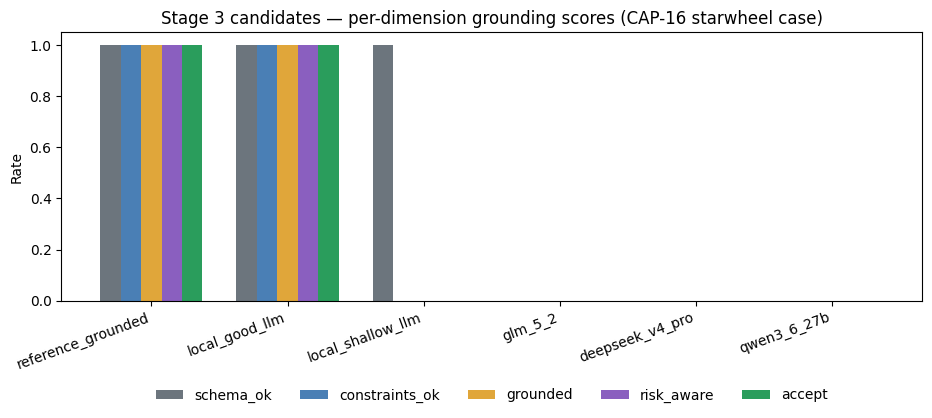

In [10]:
import matplotlib.pyplot as plt

dims = ["schema_ok_rate", "constraints_ok_rate", "grounded_rate", "risk_aware_rate", "accept_rate"]
plot_df = summary_df[dims].fillna(0)

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = range(len(plot_df))
width = 0.15
colors = ["#6c757d", "#4a7fb5", "#e0a63a", "#8a5fbf", "#2a9d5c"]
for i, dim in enumerate(dims):
    ax.bar([p + i * width for p in x], plot_df[dim], width=width, label=dim.replace("_rate", ""), color=colors[i])

ax.set_xticks([p + width * (len(dims) - 1) / 2 for p in x])
ax.set_xticklabels(plot_df.index, rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Rate")
ax.set_title("Stage 3 candidates — per-dimension grounding scores (CAP-16 starwheel case)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=5, frameon=False)
plt.tight_layout()
plt.savefig("stage3_comparison.png", dpi=150)
plt.show()

## 7.5 Debug: inspect what a failing model actually generated

The summary table above only shows the first issue as a one-liner. To
actually judge whether a failure is real (or a heuristic false-positive),
you need the full candidate JSON. This prints the first failing candidate
per model (skips models with 0 trials or where everything passed) along with
every dimension it failed and why.

In [11]:
for name, trials in all_trials.items():
    failing_candidate, failing_validation, trial_idx = None, None, None
    for t in trials:
        if t["candidates"] is None:
            failing_candidate, failing_validation, trial_idx = None, {"reasons": t["reasons"]}, t["trial"]
            break
        for c, v in zip(t["candidates"], t["validations"]):
            if v["verdict"] != "accept":
                failing_candidate, failing_validation, trial_idx = c, v, t["trial"]
                break
        if failing_validation:
            break

    if failing_validation is None:
        continue   # every candidate from this model accepted -- nothing to debug

    print(f"===== {name} -- trial {trial_idx} =====")
    if failing_candidate is None:
        print("generation itself failed:", failing_validation["reasons"])
    else:
        print(f"verdict: {failing_validation['verdict']}")
        print("dimension scores:", {
            k: failing_validation[k] for k in ("schema_ok", "constraints_ok", "grounded", "risk_aware")
        })
        print("reasons:")
        for r in failing_validation["reasons"]:
            print(" -", r)
        print()
        print(json.dumps(failing_candidate, indent=2))
    print()

===== local_shallow_llm -- trial 0 =====
verdict: reject
dimension scores: {'schema_ok': True, 'constraints_ok': False, 'grounded': False, 'risk_aware': False}
reasons:
 - outer_diameter_mm=701.6 != pcd_mm+2*pocket_radius_mm+2*rim_mm=702.20
 - rationale.pocket_clearance_mm does not reference any precedent part number or outcome-relevant keyword (SW-10231/SW-10884/clean/bind/fail/jam/precedent) -- reads as generic, not evidence-grounded
 - pocket_clearance_mm=0.4 sits closer to the FAILED precedent SW-10884 (0.35mm) than the successful one SW-10231 (0.8mm), but risk_flags is empty

{
  "branch_id": "C",
  "template_family": "starwheel_round_pocket_v3",
  "parameters": {
    "pocket_count": 16,
    "pcd_mm": 620,
    "pocket_radius_mm": 33.1,
    "pocket_clearance_mm": 0.4,
    "web_thickness_mm": 55.0,
    "rim_mm": 8.0,
    "outer_diameter_mm": 701.6,
    "lead_in_chamfer_mm": 2.0,
    "material_id": "UHMW-PE"
  },
  "rationale": {
    "pocket_count": "16 pockets is standard for this p

## 8. Reading these results

- `reference_grounded` and `local_good_llm` should both hit **1.0 accept
  rate** — two differently-worded but equally well-grounded candidates,
  proving the harness rewards actual engagement with the precedent evidence,
  not one specific phrasing.
- `local_shallow_llm` should score **low on `grounded_rate` and
  `risk_aware_rate`** even though its parameters superficially look
  plausible (right pocket_count, self-consistent geometry) — its clearance
  (0.4mm) sits closer to the *failed* precedent than the successful one, its
  rationale never names either precedent, and `risk_flags` is empty despite
  that. That's the harness working as intended: schema and hard-constraint
  checks alone would have let this design through, which is exactly why
  Stage 3 needs the grounding and risk-awareness dimensions and Stage 4/5
  don't.
- `glm_5_2`, `deepseek_v4_pro`, and `qwen3_6_27b` are the three real,
  currently-available candidates from the source doc. Their scores here are
  the actual answer to "does this model belong in Stage 3" for a given
  budget — not a demo. **Be honest about what "accept" means for these
  three in this run: this sandbox has no network access, so they show as
  `gen_failures` (skipped), not scored.** Run Section 9 with a real API key
  to get real numbers.
- **On the grading itself**: unlike Stage 4's `volume_pct_error` (an exact
  number from a real physics kernel) or Stage 1's schema match (exact string
  equality), `grounded_rate` here is a keyword heuristic over free text. A
  model could satisfy it by name-dropping "SW-10231" without engaging with
  *why* it matters, and a genuinely thoughtful rationale phrased without
  those exact keywords could be marked "not grounded." Treat every score in
  this notebook as directional evidence for a human reviewer, not a
  pass/fail gate the way Stage 4/5's checks can be. For a production
  decision, sample many past spec+precedent combinations (Stage 2's
  precedent library already has the raw material) and have a human spot-check
  a sample of the `grounded=True` and `grounded=False` calls to confirm the
  heuristic tracks real reasoning quality before trusting it at scale.

## 9. Running this for real, and what it costs

1. Get an OpenRouter key at openrouter.ai and fund the account (even a $0
   balance triggers HTTP 402 on any model, per OpenRouter's docs):
   ```bash
   export OPENROUTER_API_KEY=sk-or-...
   ```
2. **Cost is meaningfully higher than Stage 1/4's models here** — reasoning-tier
   models charge more per token, and Stage 3's prompt (spec + precedents +
   constraints + material table) plus a multi-candidate JSON response with
   embedded rationale runs longer than Stage 4's single-script prompt:
   - `z-ai/glm-5.2`: $0.50/M input, $3.15/M output. A ~1,200 input +
     ~900 output token exchange (typical for 2-3 candidates with rationale)
     costs roughly $0.0035 per call; 5 trials ≈ $0.017.
   - `deepseek/deepseek-v4-pro` at `reasoning.effort="high"`: $0.5222/M
     input, $1.044/M output — cheaper on output than GLM-5.2, but reasoning
     effort adds hidden "thinking" tokens billed as output, so real per-call
     cost is likely higher than the sticker price alone suggests. Watch the
     `usage` field in the raw response if optimizing spend.
   - `qwen/qwen3.6-27b`: $0.30/M input, $2/M output — the cheapest of the
     three, consistent with it being the source doc's "one GPU" fallback
     rather than the primary recommendation.
3. To go beyond one spec, wrap Section 6 in an outer loop over multiple
   Stage 1 spec + Stage 2 precedent-set pairs (the Stage 2 precedent library
   already has real historical data for this) and aggregate the four rates
   per model across the batch — one part's candidates, however many trials,
   still isn't a benchmark. Pay particular attention to `risk_aware_rate` on
   a batch that includes several genuinely risky precedent sets (not just
   this one clean CAP-16 case) — that's the dimension most likely to reveal
   real differences between the three candidates, since it's the one the
   source doc explicitly ties to model scale.
4. If a real run shows `deepseek_v4_pro`'s `xhigh` reasoning effort changes
   `grounded_rate` or `risk_aware_rate` versus `high`, that's worth
   capturing as its own finding — reasoning effort is a lever this notebook
   only tests at one setting.

## References

- GLM 5.2 — model id and pricing: https://openrouter.ai/z-ai/glm-5.2
- GLM 5.2 — per-provider endpoint pricing: https://openrouter.ai/api/v1/models/z-ai/glm-5.2/endpoints
- DeepSeek V4 Pro — model id and pricing: https://openrouter.ai/deepseek/deepseek-v4-pro
- DeepSeek V4 Pro — per-provider endpoint pricing: https://openrouter.ai/api/v1/models/deepseek/deepseek-v4-pro/endpoints
- DeepSeek V4 Flash (substitution alternative, not used as primary) — https://openrouter.ai/deepseek/deepseek-v4-flash
- Qwen3.6 27B — model id and pricing: https://openrouter.ai/qwen/qwen3.6-27b
- Qwen3.6 27B — per-provider endpoint pricing: https://openrouter.ai/api/v1/models/qwen/qwen3.6-27b/endpoints
- OpenRouter models API (used for the cross-check pass): https://openrouter.ai/api/v1/models